# MCDI505 — Sumativa 03
## Modelos avanzados de series de tiempo (ARFIMA / GARCH)
**Estudiante:** Luis Rodrigo Espinoza Muñoz  
**Docente:** Dr. Harvey Jezlid Rosas Quintero  
**Fecha:** 17 de octubre de 2026  
**Archivo:** `mcdi505_s3lespinoza.ipynb`  
**Datos:** `data/raw/consumo_electrico_litoral_depurado.csv`  
**Figuras:** `results/figures/`

En esta entrega evalúo si la memoria larga o la volatilidad condicional mejoran el pronóstico SARIMA que seleccioné en Formativa 2.

## Hoja de decisiones — revisada para Sumativa 3
**Luis Rodrigo Espinoza Muñoz · MCDI505 · 17 de octubre de 2026**  
Base: M4 de Formativa 2, SARIMA(0,1,0)(1,1,0)₁₂; entrenamiento 2015–2022; validación 2023. **2024 excluido.**

| Criterio | Decisión o conclusión | Evidencia clave | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Memoria larga | No hay evidencia conjunta suficiente para añadir memoria larga; H > 0,5 puede ser falso positivo. | n = 83; H = 0,5837; d = 0,0837. ACF hasta 36 sin decaimiento positivo lento; ACF(24) = −0,3495. ARFIMA eleva RMSE a 4,1922 frente a 4,1214 GWh (Tabla 1, Figuras 1 y 3). | Inferir memoria larga solo por H o por ADF; adoptar ARFIMA(0,d,0) por complejidad. | Mantener SARIMA; revisar el pico en 24. Ruido blanco simulado: 83,65 % supera H = 0,5 (sección 1). |
| 2. Volatilidad | Sin evidencia suficiente de heterocedasticidad condicional al 5 %; GARCH se estima como contraste. | LB residuos²(12): p = 0,8287; ARCH-LM: p = 0,7863. GARCH: ω = 0,1564 normalizado (0,0003 log²), α = 0,0687; β = 0,7716; α + β = 0,8403. Converge; LB z²: p = 0,8535 (Tabla 2, Figura 2). | Interpretar persistencia positiva como prueba de necesidad de GARCH. | Conservar bandas SARIMA; no confundir falta de rechazo con prueba de varianza constante. |
| 3. Contraste | La corrección ARFIMA no mejora; bandas GARCH apenas se estrechan. | Tabla resumida debajo; ARFIMA empeora RMSE 1,72 %. Ambos intervalos cubren 12/12; reducción de ancho 1,34 % (Tabla 3, Figura 3). | Comparar AIC de media y varianza o concluir calibración por 12 meses. | Preferir parsimonia; reconocer la reutilización de validación 2023. |
| 4. Selección | Mantener SARIMA(0,1,0)(1,1,0)₁₂, sin exógenas ni constante. | RMSE 4,1214 GWh; mejora 43,26 % frente al naive; ARCH-LM p = 0,7863, en conjunto con el diagnóstico de memoria (Tabla 4, Figura 4). | Añadir ARFIMA o GARCH sin ganancia sustentada. | Llevar la especificación a Semana 4. Limitación principal: solo 12 meses de validación y 83 residuos; no evaluar 2024 ahora. |

**Validación 2023: errores y ancho en GWh; intervalos nominales del 95 %.**

| Modelo | RMSE | MAE | Cobertura | Ancho medio |
|---|---:|---:|---:|---:|
| SARIMA | 4,1214 | 3,7089 | 100 % (12/12) | 46,2602 |
| SARIMA + ARFIMA(0,0,0837,0) | 4,1922 | 3,7492 | No evaluada | No evaluado |
| Naive estacional | 7,2630 | 6,5283 | No evaluada | No evaluado |
| SARIMA + bandas GARCH | 4,1214 | 3,7089 | 100 % (12/12) | 45,6387 |

GARCH conserva el punto SARIMA y modifica solo las bandas mediante la aproximación de la plantilla. Las cifras se reproducen en el desarrollo. Una conclusión negativa se apoya en evidencia conjunta, no únicamente en p > 0,05.

## 0. Reproducibilidad del entorno y carga del dataset

Ejecuté todas las celdas en orden en un kernel nuevo de IPython (ejecución local en proceso, sin estado previo). Para reproducir el análisis, usa **Restart Kernel and Run All**. Descarga o clona el repositorio para tener `requirements.txt` y `data/raw/consumo_electrico_litoral_depurado.csv`. La instalación de dependencias requiere Internet; después, el análisis usa el CSV local.

La raíz del proyecto se detecta automáticamente desde la carpeta principal, `notebooks/` o `notebooks/notebook_formativa/`. Se usan rutas con `pathlib`, compatibles con macOS, Windows y Linux. Todas las figuras se muestran dentro del notebook y se guardan como PNG en `results/figures/`.

**Instalación local en macOS o Linux (desde la raíz del repositorio):**

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install -r requirements.txt
python -m ipykernel install --user --name mcdi505 --display-name "Python (MCDI505)"
jupyter lab
```

**Instalación local en Windows PowerShell (desde la raíz del repositorio):**

```powershell
py -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install --upgrade pip
python -m pip install -r requirements.txt
python -m ipykernel install --user --name mcdi505 --display-name "Python (MCDI505)"
jupyter lab
```

Si PowerShell bloquea la activación, ejecutar `Set-ExecutionPolicy -Scope Process -ExecutionPolicy Bypass` y volver a activar el entorno. Seleccionar el kernel **Python (MCDI505)**, abrir `notebooks/notebook_formativa/mcdi505_s3lespinoza.ipynb` y ejecutar todas las celdas en orden. El entorno `.venv` se crea en cada computador; no se copia entre sistemas operativos.

**Google Colab:** subir el notebook y ejecutar primero en una celda adicional:

```python
%pip install pandas numpy scipy matplotlib statsmodels jinja2
```

En el panel de archivos, crear `data/raw/` dentro del directorio de trabajo y subir allí `consumo_electrico_litoral_depurado.csv`. Luego ejecutar el notebook desde el inicio. No se necesita `.venv` ni registrar un kernel local. Al terminar, descargar el notebook ejecutado y las figuras de `results/figures/`, ya que los archivos del entorno de Colab son temporales. El CSV debe acompañar al notebook: no se ha configurado una fuente pública de respaldo.

Las versiones usadas aparecen en la salida de configuración; con otras versiones pueden variar ligeramente las cifras. Si no tienes `requirements.txt`, instala `numpy pandas scipy matplotlib statsmodels jinja2 ipykernel jupyterlab` en el entorno activo. No necesito `arch`: implemento GARCH con `scipy.optimize.minimize`.

Cargo el CSV depurado sin modificarlo ni repetir sus correcciones. Uso 2015–2022 para entrenamiento y 2023 para validación; 2024 queda reservado. Registro las versiones y la huella SHA-256 del archivo. La semilla se fija en 505, aunque los ajustes utilizados son deterministas.

Las figuras se muestran en el notebook y también se guardan en `results/figures/`. El CSV debe permanecer en `data/raw/` para volver a ejecutar el análisis.

In [1]:
# Importo las herramientas que uso para el análisis y los gráficos.
from pathlib import Path
import sys, hashlib, warnings, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.optimize import minimize
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tools.sm_exceptions import InterpolationWarning

# Fijo la semilla, el nivel de significancia y el período anual.
SEMILLA, ALFA, PERIODO = 505, 0.05, 12
np.random.seed(SEMILLA)
# Silencio este aviso de API, pero dejo visibles los avisos de convergencia.
warnings.filterwarnings('ignore', category=FutureWarning, message='.*currently returns a plain tuple.*')
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
# Busco la raíz del proyecto desde la carpeta de ejecución.
nombre_csv = 'consumo_electrico_litoral_depurado.csv'
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / 'data/raw' / nombre_csv).is_file()), None
)
if project_root is None:
    raise FileNotFoundError('Ejecuta el notebook dentro del proyecto que contiene data/raw/consumo_electrico_litoral_depurado.csv.')

# Guardo las figuras en la carpeta de resultados.
FIGURAS = project_root / 'results/figures'
FIGURAS.mkdir(parents=True, exist_ok=True)
def mostrar_figura(fig, nombre):
    # Ajusto, guardo y muestro cada figura.
    fig.tight_layout()
    fig.savefig(FIGURAS / nombre, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# Leo el CSV depurado desde data/raw/.
ruta = project_root / 'data/raw' / nombre_csv
# Registro la huella para comprobar qué versión de datos uso.
sha256 = hashlib.sha256(ruta.read_bytes()).hexdigest()
sha_esperado = 'd308b3605bf47ed8687676906a130362d899cfcf5e40329a39c9074078c0c3d1'
print('SHA-256:', sha256)
if sha256 != sha_esperado:
    warnings.warn('El archivo difiere en bytes del analizado; revise procedencia y resultados.')
# Cargo los datos y reviso fechas y columnas.
df = pd.read_csv(ruta, parse_dates=['fecha'], index_col='fecha')
assert df.index.is_unique and df.index.is_monotonic_increasing
assert {'consumo_gwh','consumo_gwh_original','imputado','atipico_corregido','covid'} <= set(df.columns)
# Compruebo el calendario sin usar valores de consumo de 2024.
assert df.index.equals(pd.date_range(df.index.min(), df.index.max(), freq='MS'))
# Separo entrenamiento y validación; dejo 2024 reservado.
datos = df.loc['2015-01':'2023-12'].copy().asfreq('MS')
y = datos['consumo_gwh'].astype(float)
assert len(y) == 108 and y.notna().all() and np.isfinite(y).all() and (y > 0).all()
# Compruebo que entrenamiento quede antes de la validación.
y_train, y_val = y.loc['2015':'2022'], y.loc['2023']
assert len(y_train) == 96 and len(y_val) == 12
assert y_train.index.max() < y_val.index.min()
# Reviso las correcciones e indicadores del archivo depurado.
assert int(datos.imputado.sum()) == 3 and int(datos.atipico_corregido.sum()) == 1
assert datos.loc['2017-11-01','atipico_corregido'] == 1
assert datos.covid.astype(bool).equals(pd.Series(
    (datos.index >= '2020-03-01') & (datos.index <= '2021-12-01'), index=datos.index))
# Transformo solo los datos de entrenamiento.
z_train = np.log(y_train)
print('Entrenamiento: 2015-01 a 2022-12 (96 meses). Validación: 2023 (12 meses).')
print('2024 excluido de gráficos, estimación, selección y métricas.')
print('Indicadores 2015–2023:', datos[['imputado','atipico_corregido','covid']].sum().to_dict())
print('Python:', sys.version.split()[0])
print('Versiones:', {p: metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','matplotlib','jinja2']})

SHA-256: d308b3605bf47ed8687676906a130362d899cfcf5e40329a39c9074078c0c3d1
Entrenamiento: 2015-01 a 2022-12 (96 meses). Validación: 2023 (12 meses).
2024 excluido de gráficos, estimación, selección y métricas.
Indicadores 2015–2023: {'imputado': 3, 'atipico_corregido': 1, 'covid': 22}
Python: 3.10.4
Versiones: {'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy': '1.15.3', 'statsmodels': '0.15.0', 'matplotlib': '3.10.9', 'jinja2': '3.1.6'}


### Datos y modelo heredado
DEL representa consumo eléctrico comercial mensual en GWh. Se conserva el CSV depurado, sin nuevas imputaciones ni exclusión del shock de 2020. El modelo heredado es **M4: SARIMA(0,1,0)(1,1,0)₁₂**, sin constante ni regresores, ajustado al logaritmo de 2015–2022 (Box et al., 2015). Se mantienen las restricciones de estacionariedad e invertibilidad y la inicialización del notebook anterior.

Los modelos avanzados se estiman sobre **83 innovaciones de entrenamiento**, tras retirar 13 observaciones iniciales. Ningún parámetro se estima con 2023. La validación compara doce pronósticos con origen fijo en diciembre de 2022; 2024 permanece reservado (UNAB, s. f.-a; Rosas, 2026).

### Funciones de apoyo
Uso las siete funciones entregadas en la plantilla. `HORIZONTE` representa los doce meses y llamo `hurst_rs` al exponente para distinguirlo de la función. Estimo la corrección fraccional con R/S y **d = H − 0,5**; no ajusto un SARIMA–ARFIMA por máxima verosimilitud.

Tomo la selección de Formativa 2 como punto de partida y no repito la búsqueda de SARIMA. Reviso si Hurst, la dependencia residual y la validación respaldan añadir memoria larga. ADF prueba raíz unitaria (Dickey & Fuller, 1979), pero por sí sola no identifica memoria larga.

In [2]:
# Uso estas funciones de apoyo para memoria larga y volatilidad.

def calcular_exponente_hurst(serie, min_ventana=8, max_ventana=None, n_ventanas=10):
    """Exponente de Hurst por Rango Reescalado (R/S). Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    if max_ventana is None:
        max_ventana = n // 4
    ventanas = np.unique(np.geomspace(min_ventana, max_ventana, num=n_ventanas, dtype=int))
    rs_promedio, ventanas_validas = [], []
    for w in ventanas:
        m = n // w
        if m < 1:
            continue
        rs_bloques = []
        for i in range(m):
            bloque = serie[i * w:(i + 1) * w]
            recorrido = np.cumsum(bloque - np.mean(bloque))
            desviacion = np.std(bloque)
            if desviacion > 0:
                rs_bloques.append((np.max(recorrido) - np.min(recorrido)) / desviacion)
        if rs_bloques:
            rs_promedio.append(np.mean(rs_bloques))
            ventanas_validas.append(w)
    pendiente, _ = np.polyfit(np.log(ventanas_validas), np.log(rs_promedio), 1)
    return pendiente


def aplicar_filtro_fraccional(serie, d):
    """Operador (1-B)^d. d > 0 diferencia fraccionalmente; d < 0 integra. Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    pesos = np.zeros(n)
    pesos[0] = 1.0
    for k in range(1, n):
        pesos[k] = pesos[k - 1] * (k - 1 - d) / k
    return np.array([np.sum(pesos[:t + 1] * serie[t::-1]) for t in range(n)])


def garch_log_verosimilitud_negativa(parametros, serie):
    """Log-verosimilitud negativa de un GARCH(1,1) gaussiano. Ver Sesión 3, §3.4."""
    omega, alpha, beta = parametros
    sigma2 = np.zeros(len(serie))
    sigma2[0] = np.var(serie)
    for t in range(1, len(serie)):
        sigma2[t] = omega + alpha * serie[t - 1] ** 2 + beta * sigma2[t - 1]
    if np.any(sigma2 <= 1e-8):
        return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + serie ** 2 / sigma2)


def correccion_arfima(residuos, d, h):
    """Pronóstico h pasos del componente ARFIMA(0,d,0) de los residuos.

    Diferencia fraccionalmente los residuos con d, pronostica cero (ruido blanco)
    y vuelve a integrar con -d. Lo que queda es la persistencia que la memoria
    larga añadiría al pronóstico del SARIMA (en escala logarítmica).
    """
    r = np.asarray(residuos, dtype=float)
    extendida = np.concatenate([aplicar_filtro_fraccional(r, d), np.zeros(h)])
    return aplicar_filtro_fraccional(extendida, -d)[len(r):]


def estimar_garch11(residuos, h):
    """Estima un GARCH(1,1) por MLE sobre los residuos estandarizados.

    Devuelve un diccionario con omega, alpha, beta, persistencia, convergencia,
    residuos estandarizados por sigma_t y el factor de escala de la desviación
    estándar condicional para los h meses siguientes (1 = igual a la varianza
    incondicional).
    """
    r = np.asarray(residuos, dtype=float)
    s = r.std()
    u = r / s
    res = minimize(garch_log_verosimilitud_negativa, x0=[0.05, 0.10, 0.80], args=(u,),
                   bounds=[(1e-6, 5.0), (1e-6, 0.999), (1e-6, 0.999)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]},),
                   method="SLSQP")
    om, al, be = res.x
    sigma2 = np.zeros(len(u)); sigma2[0] = u.var()
    for t in range(1, len(u)):
        sigma2[t] = om + al * u[t - 1] ** 2 + be * sigma2[t - 1]
    futura = np.zeros(h)
    futura[0] = om + al * u[-1] ** 2 + be * sigma2[-1]
    for i in range(1, h):
        futura[i] = om + (al + be) * futura[i - 1]
    incondicional = om / (1 - al - be)
    return {"omega": om, "alpha": al, "beta": be, "persistencia": al + be,
            "convergencia": bool(res.success),
            "residuos_estandarizados": u / np.sqrt(sigma2),
            "escala_futura": np.sqrt(futura / incondicional)}


def metricas(real, pred):
    """RMSE y MAE en la escala de los datos (GWh)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}


def cobertura_y_ancho(real, inferior, superior):
    """Proporción de meses dentro del intervalo y ancho promedio del intervalo (GWh)."""
    real, inferior, superior = (np.asarray(x, float) for x in (real, inferior, superior))
    return {"Cobertura": float(np.mean((real >= inferior) & (real <= superior))),
            "Ancho medio": float(np.mean(superior - inferior))}

In [3]:
# Repito la especificación que seleccioné en Formativa 2.
# Defino el orden no estacional y el estacional del SARIMA.
ORDEN, ORDEN_ESTACIONAL = (0,1,0), (1,1,0,12)
USAR_COVID = False
HORIZONTE = 12
sarima = SARIMAX(z_train, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL,
                 trend='n', enforce_stationarity=True, enforce_invertibility=True,
                 simple_differencing=False).fit(method='lbfgs', maxiter=500, disp=False)
# Si lbfgs no converge, pruebo Powell.
if not sarima.mle_retvals.get('converged', False):
    sarima = sarima.model.fit(method='powell', maxiter=1000, disp=False)
assert sarima.mle_retvals.get('converged',False)
# Retiro las observaciones de inicialización antes de revisar los residuos.
model_df = ORDEN[0]+ORDEN[2]+ORDEN_ESTACIONAL[0]+ORDEN_ESTACIONAL[2]
inicio = max(int(sarima.loglikelihood_burn), ORDEN[1]+ORDEN_ESTACIONAL[1]*12)
residuos = sarima.resid.iloc[inicio:].dropna()
assert len(residuos)==83 and np.isfinite(residuos).all()
# Pronostico los doce meses desde diciembre de 2022.
pron = sarima.get_forecast(steps=HORIZONTE)
media_log, var_log = pron.predicted_mean, pron.var_pred_mean
ic_log = pron.conf_int(alpha=ALFA)
sd_log = np.sqrt(var_log)
# Preparo el naive estacional como referencia.
naive = pd.Series(y_train.iloc[-12:].to_numpy(), index=y_val.index)
assert media_log.index.equals(y_val.index)
print(f'SARIMA{ORDEN}{ORDEN_ESTACIONAL}; convergencia: {sarima.mle_retvals["converged"]}')
print(f'AIC={sarima.aic:.6f}; BIC={sarima.bic:.6f}; descarte={inicio}; n residual={len(residuos)}')
display(sarima.params.to_frame('Estimación'))

SARIMA(0, 1, 0)(1, 1, 0, 12); convergencia: True
AIC=-277.806414; BIC=-272.968733; descarte=13; n residual=83


,Estimación
ar.S.L12,-0.3109
sigma2,0.0019


## 1. Modelamiento de memoria larga (ARFIMA / diferenciación fraccional)
**ID 3.1.** Se examinan Hurst, d y ACF hasta 36 meses conjuntamente. R/S con 83 residuos utiliza ventanas de apenas 8–20 meses: puede sobrestimar H y no permite identificar con precisión una ley de decaimiento a largo plazo. Las bandas de ACF son puntuales y aproximadas, no una prueba conjunta. ADF no distingue memoria corta de memoria fraccional estacionaria (Rosas, 2026).

Se aplica `(1−B)^d` a los residuos y se pronostican innovaciones futuras nulas; la integración inversa entrega la corrección logarítmica. El contraste predictivo se presenta en la sección 3.

**Fundamento metodológico:** el análisis R/S se vincula con Hurst (1951) y la diferenciación fraccional con Hosking (1981). La implementación docente aproxima d mediante H − 0,5; no equivale a estimar conjuntamente un ARFIMA por máxima verosimilitud.

Tabla 1. n=83; Hurst R/S=0.583659; d=0.083659; banda ACF ±0.2151


,Rezago,ACF
0,1,-0.0171
1,12,-0.1246
2,24,-0.3495
3,36,-0.0233


Corrección ARFIMA logarítmica a 12 pasos: [-0.003666 -0.001713 -0.00105  -0.000724 -0.000533 -0.000409 -0.000324
 -0.000263 -0.000217 -0.000182 -0.000155 -0.000133]
Ljung–Box del componente filtrado (exploratorio; d estimado, p-valores aproximados):


,lb_stat,lb_pvalue
12,9.2509,0.6814
24,37.1052,0.0427


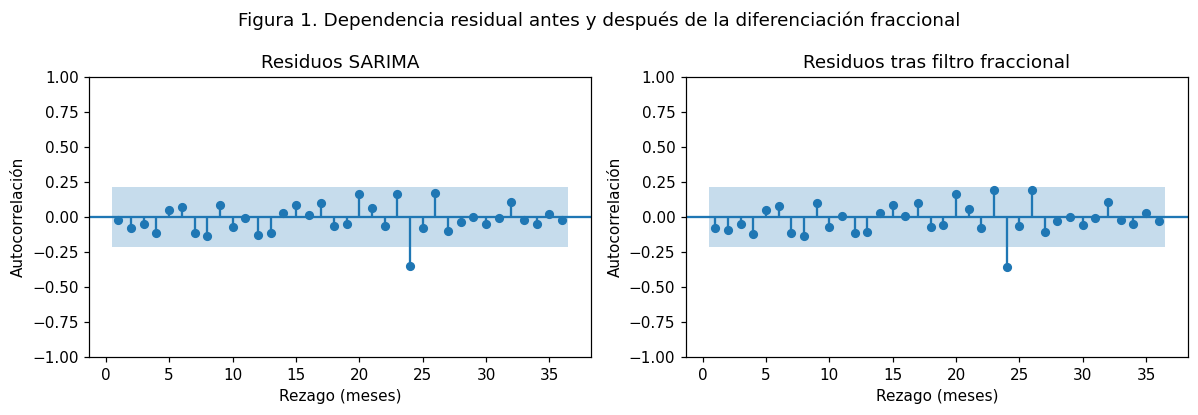

Sensibilidad R/S con 2000 ruidos blancos de n=83:
Cuantiles 2,5%, 50%, 97,5%: [0.3935 0.6108 0.8231]
Proporción H>0,5: 83.65%; fracción en cola ≥ H observado: 0.6047
Referencia Monte Carlo bajo ruido blanco iid gaussiano; no reproduce la estimación previa del SARIMA.


In [4]:
# Estimo Hurst y obtengo d para la corrección fraccional.
hurst_rs = float(calcular_exponente_hurst(residuos))
d_frac = hurst_rs - .5
assert -.5 < d_frac < .5, 'Revisar d antes de interpretar un ARFIMA estacionario/invertible.'
correccion = correccion_arfima(residuos, d_frac, HORIZONTE)
res_frac = pd.Series(aplicar_filtro_fraccional(residuos, d_frac), index=residuos.index)
# Reviso la autocorrelación hasta 36 meses.
acf_r = acf(residuos, nlags=36, fft=False)
banda_acf = 1.96/np.sqrt(len(residuos))
lb_frac = acorr_ljungbox(res_frac, lags=[12,24], model_df=0, return_df=True)
print(f'Tabla 1. n={len(residuos)}; Hurst R/S={hurst_rs:.6f}; d={d_frac:.6f}; banda ACF ±{banda_acf:.4f}')
display(pd.DataFrame({'Rezago':[1,12,24,36], 'ACF':acf_r[[1,12,24,36]]}))
print('Corrección ARFIMA logarítmica a 12 pasos:',np.round(correccion,6))
print('Ljung–Box del componente filtrado (exploratorio; d estimado, p-valores aproximados):')
display(lb_frac)
# Comparo la ACF antes y después del filtro fraccional.
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
plot_acf(residuos,lags=36,zero=False,bartlett_confint=False,ax=ax[0])
plot_acf(res_frac,lags=36,zero=False,bartlett_confint=False,ax=ax[1])
for a,t in zip(ax,['Residuos SARIMA','Residuos tras filtro fraccional']):
    a.set(title=t,xlabel='Rezago (meses)',ylabel='Autocorrelación')
fig.suptitle('Figura 1. Dependencia residual antes y después de la diferenciación fraccional')
mostrar_figura(fig,'s3_01_memoria.png')
# Reviso el sesgo R/S con ruido blanco del mismo tamaño.
# Tomo esta simulación como referencia, no como prueba de memoria larga.
# Uso una semilla fija para poder repetir la simulación.
rng = np.random.default_rng(SEMILLA)
N_SIM = 2000
hurst_blanco = np.array([calcular_exponente_hurst(rng.normal(size=len(residuos))) for _ in range(N_SIM)])
q_h = np.quantile(hurst_blanco,[.025,.5,.975])
cola_h = (1+np.sum(hurst_blanco>=hurst_rs))/(N_SIM+1)
print(f'Sensibilidad R/S con {N_SIM} ruidos blancos de n={len(residuos)}:')
print('Cuantiles 2,5%, 50%, 97,5%:', np.round(q_h,4))
print(f'Proporción H>0,5: {np.mean(hurst_blanco>.5):.2%}; fracción en cola ≥ H observado: {cola_h:.4f}')
print('Referencia Monte Carlo bajo ruido blanco iid gaussiano; no reproduce la estimación previa del SARIMA.')


### Interpretación

Con 83 residuos, H = 0,5837 y d = 0,0837 sugieren persistencia leve según R/S, pero no prueban memoria larga. Las ventanas de 8–20 meses y el tamaño reducido favorecen sesgo positivo. En 2.000 simulaciones de ruido blanco de igual longitud, el 83,65 % supera H = 0,5 y la mediana es 0,6108; su cola es una referencia exploratoria, no un p-valor formal que contemple la estimación SARIMA.

La ACF hasta 36 no presenta una sucesión positiva de decaimiento lento: ACF(1) = −0,0171, ACF(12) = −0,1246, ACF(24) = −0,3495 y ACF(36) = −0,0233. El pico negativo en 24 merece seguimiento de la estructura estacional, pero no constituye el patrón esperado de memoria larga positiva. Las bandas ±0,2151 son puntuales y se inspeccionan múltiples rezagos.

Se estima el contraste mínimo ARFIMA(0,0,0837,0) mediante el procedimiento de la plantilla. El filtro no elimina toda dependencia: Ljung–Box exploratorio del componente filtrado arroja p = 0,0427 en 24. Su interpretación es aproximada por haber estimado d y por los efectos de borde del filtro.

En 2023, la corrección eleva RMSE de 4,1214 a 4,1922 GWh y MAE de 3,7089 a 3,7492 (Tabla 3). No hay respaldo conjunto suficiente para incorporar memoria larga. Esto no demuestra su inexistencia: la evidencia es limitada y la validación tiene doce meses. ADF no resuelve esta cuestión, pues un proceso fraccional estacionario también puede rechazar raíz unitaria.

## 2. Modelamiento de volatilidad (GARCH)
**ID 3.1.** Se contrastan ausencia de autocorrelación de los cuadrados mediante Ljung–Box(12) y ausencia de efectos ARCH mediante ARCH-LM(12), con α = 0,05. El ARCH-LM principal utiliza `ddof=0`, como la plantilla; se añade `ddof=1` para reconciliar el resultado de Semana 2. No rechazar no demuestra homocedasticidad.

`estimar_garch11` divide los residuos por su desviación (ddof=0), sin centrar, y estima una media condicional residual nula. **ω se informa tanto en esa escala normalizada como en unidades de error logarítmico al cuadrado**; α y β no cambian con la escala. Se exige ω > 0, α, β ≥ 0 y α + β < 1. Los diagnósticos posteriores se aplican a residuos divididos por σₜ, y a sus cuadrados.

**Fundamento metodológico:** ARCH y su contraste se apoyan en Engle (1982); la recursión GARCH(1,1), en Bollerslev (1986); el diagnóstico de autocorrelación, en Ljung y Box (1978).

Tabla 2a. Diagnósticos (z: residuos estandarizados por volatilidad condicional).


,Estadístico,p
Prueba,,
Ljung–Box residuos² (12),7.4190,0.8287
"ARCH-LM (12), ddof=0",7.9851,0.7863
"ARCH-LM (12), ddof=1: continuidad S2",7.8726,0.7950
Ljung–Box z (12),8.2473,0.7655
Ljung–Box z² (12),7.0626,0.8535
ARCH-LM z (12),8.5549,0.7404


Tabla 2b. Parámetros GARCH(1,1).


,Estimación
omega normalizado,0.1564
omega log²,0.0003
alpha,0.0687
beta,0.7716
alpha+beta,0.8403
varianza incondicional log²,0.0019


Convergencia: True ; escala futura: [0.964407 0.970178 0.975002 0.979036 0.982414 0.985243 0.987614 0.989603
 0.99127  0.992669 0.993844 0.994829]


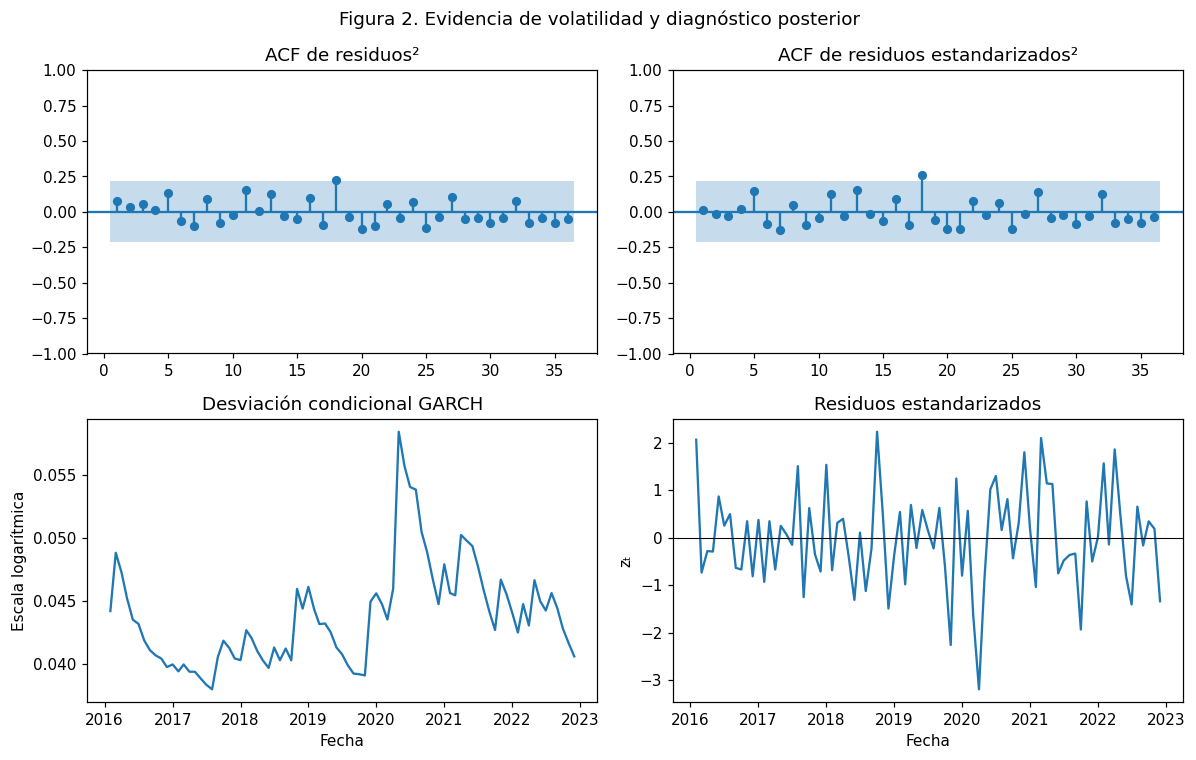

In [5]:
# Pruebo autocorrelación en residuos al cuadrado y efectos ARCH.
lb_cuadrados = acorr_ljungbox(residuos**2, lags=[12], return_df=True)
arch_lm = het_arch(residuos,nlags=12,ddof=0)
arch_lm_s2 = het_arch(residuos,nlags=12,ddof=model_df)
# Estimo GARCH(1,1) y reviso su convergencia.
g = estimar_garch11(residuos,HORIZONTE)
assert g['convergencia'], 'No interpretar un GARCH sin convergencia.'
assert g['omega']>0 and g['alpha']>=0 and g['beta']>=0 and g['persistencia']<1
# Vuelvo a la escala original de los residuos para expresar omega.
s_res = np.std(residuos.to_numpy(),ddof=0)
omega_log = g['omega']*s_res**2
u = residuos.to_numpy()/s_res
sigma2_u = np.empty(len(u)); sigma2_u[0]=np.var(u)
for t in range(1,len(u)):
    sigma2_u[t]=g['omega']+g['alpha']*u[t-1]**2+g['beta']*sigma2_u[t-1]
sigma_log = pd.Series(np.sqrt(sigma2_u)*s_res,index=residuos.index)
z_g = pd.Series(g['residuos_estandarizados'],index=residuos.index)
assert np.allclose(z_g,residuos/sigma_log)
# Compruebo los residuos estandarizados y sus cuadrados.
lb_z = acorr_ljungbox(z_g,lags=[12],return_df=True)
lb_z2 = acorr_ljungbox(z_g**2,lags=[12],return_df=True)
arch_z = het_arch(z_g,nlags=12)
tabla2 = pd.DataFrame([
    ['Ljung–Box residuos² (12)',lb_cuadrados.iloc[0,0],lb_cuadrados.iloc[0,1]],
    ['ARCH-LM (12), ddof=0',arch_lm[0],arch_lm[1]],
    ['ARCH-LM (12), ddof=1: continuidad S2',arch_lm_s2[0],arch_lm_s2[1]],
    ['Ljung–Box z (12)',lb_z.iloc[0,0],lb_z.iloc[0,1]],
    ['Ljung–Box z² (12)',lb_z2.iloc[0,0],lb_z2.iloc[0,1]],
    ['ARCH-LM z (12)',arch_z[0],arch_z[1]]],columns=['Prueba','Estadístico','p']).set_index('Prueba')
print('Tabla 2a. Diagnósticos (z: residuos estandarizados por volatilidad condicional).')
display(tabla2)
print('Tabla 2b. Parámetros GARCH(1,1).')
display(pd.Series({'omega normalizado':g['omega'],'omega log²':omega_log,
                   'alpha':g['alpha'],'beta':g['beta'],'alpha+beta':g['persistencia'],
                   'varianza incondicional log²':omega_log/(1-g['persistencia'])}).to_frame('Estimación'))
print('Convergencia:',g['convergencia'],'; escala futura:',np.round(g['escala_futura'],6))
# Grafico la volatilidad estimada y los diagnósticos posteriores.
fig,ax=plt.subplots(2,2,figsize=(11,7))
plot_acf(residuos**2,lags=36,zero=False,bartlett_confint=False,ax=ax[0,0])
plot_acf(z_g**2,lags=36,zero=False,bartlett_confint=False,ax=ax[0,1])
ax[0,0].set_title('ACF de residuos²');ax[0,1].set_title('ACF de residuos estandarizados²')
ax[1,0].plot(sigma_log);ax[1,0].set(title='Desviación condicional GARCH',ylabel='Escala logarítmica',xlabel='Fecha')
ax[1,1].plot(z_g);ax[1,1].axhline(0,color='black',lw=.7)
ax[1,1].set(title='Residuos estandarizados',ylabel='zₜ',xlabel='Fecha')
fig.suptitle('Figura 2. Evidencia de volatilidad y diagnóstico posterior')
mostrar_figura(fig,'s3_02_volatilidad.png')

### Interpretación

Ljung–Box sobre residuos² da p = 0,8287 y ARCH-LM(12), p = 0,7863: no se rechazan sus hipótesis nulas al 5 %. Con ddof = 1, ARCH-LM entrega p = 0,7950, coherente con Semana 2. La ACF de cuadrados complementa las pruebas; ninguna acredita homocedasticidad absoluta con esta muestra.

El GARCH(1,1) converge con ω = 0,1564 en escala normalizada (0,0003 en error logarítmico²), α = 0,0687 y β = 0,7716. α mide la respuesta a shocks recientes y β la continuidad de la varianza previa. La persistencia α + β = 0,8403 es menor que uno: el efecto esperado de un shock se disipa y la varianza revierte a su nivel de largo plazo, bajo la especificación ajustada. No se calcularon errores estándar; no se atribuye significancia estadística a los coeficientes.

Los residuos estandarizados no presentan rechazo en Ljung–Box(12), p = 0,7655; sus cuadrados tampoco, p = 0,8535, ni ARCH-LM, p = 0,7404. Son controles aproximados posteriores a estimación, no pruebas de validez definitiva.

Las bandas resultan apenas más estrechas y cubren los mismos doce meses que SARIMA. Una persistencia positiva estimada no contradice la falta de evidencia en las pruebas, ni demuestra necesidad de GARCH. Para consumo comercial mensual, no se justifica adoptarlo solo por analogía con series financieras; se conserva como contraste.

## 3. Contraste con el modelo clásico y consistencia de conclusiones
**ID 3.1.** Se comparan fechas, horizonte y escala comunes. Se conserva la media lognormal de Semana 2: `exp(media_log + var_log/2)`. Para el ARFIMA se añade la corrección a la media logarítmica y se mantiene la varianza predictiva SARIMA como aproximación de contraste; no se afirma haber estimado toda la incertidumbre del modelo compuesto.

Las bandas GARCH siguen la receta docente: `exp(media_log ± 1,96 · sd_log · escala_futura)`. Son **bandas ajustadas heurísticamente**, no intervalos de un SARIMA–GARCH estimado conjuntamente ni propagación exacta de varianza a doce pasos. GARCH modifica aquí las bandas, conservando el pronóstico puntual del SARIMA. La cobertura observada no garantiza calibración al 95 % (plantilla UNAB, s. f.-b).

Tabla 3. Validación 2023; errores y ancho en GWh, cobertura en proporción.


,RMSE,MAE,Cobertura,Ancho medio,Meses cubiertos
Modelo,,,,,
SARIMA,4.1214,3.7089,100.00%,46.2602,12
SARIMA + ARFIMA,4.1922,3.7492,No evaluado,No evaluado,No evaluado
Naive estacional,7.2630,6.5283,No evaluado,No evaluado,No evaluado
SARIMA + bandas GARCH,4.1214,3.7089,100.00%,45.6387,12


Cambio RMSE favorable a ARFIMA: -1.717%; mejora SARIMA frente a naive: 43.255%
No se compara AIC de modelos de media con AIC de modelos de varianza.


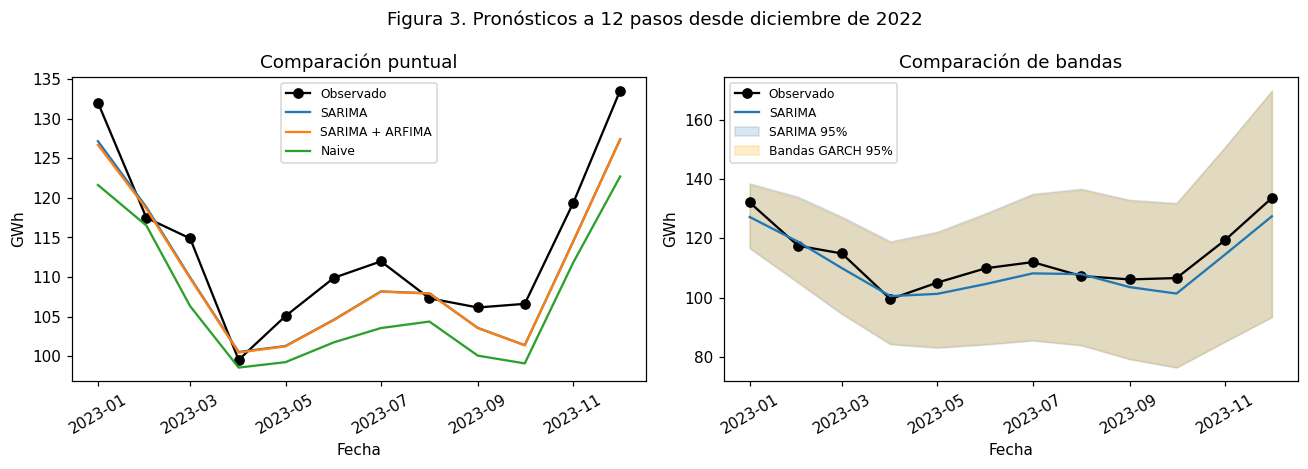

In [6]:
# Vuelvo a GWh con la corrección lognormal.
pred_sarima = np.exp(media_log+.5*var_log)
pred_arfima = np.exp(media_log+correccion+.5*var_log)
# Construyo los intervalos SARIMA y las bandas GARCH.
ic_sarima = np.exp(ic_log)
ic_garch = pd.DataFrame({'Inferior':np.exp(media_log-1.96*sd_log*g['escala_futura']),
                         'Superior':np.exp(media_log+1.96*sd_log*g['escala_futura'])},index=y_val.index)
# Comparo los modelos en las mismas fechas de validación.
filas=[]
for nombre,pred,ic in [('SARIMA',pred_sarima,ic_sarima),
                       ('SARIMA + ARFIMA',pred_arfima,None),
                       ('Naive estacional',naive,None),
                       ('SARIMA + bandas GARCH',pred_sarima,ic_garch)]:
    fila={'Modelo':nombre,**metricas(y_val,pred)}
    if ic is not None:
        assert (ic.iloc[:,1]>=ic.iloc[:,0]).all()
        fila.update(cobertura_y_ancho(y_val,ic.iloc[:,0],ic.iloc[:,1]))
        fila['Meses cubiertos']=int(((y_val>=ic.iloc[:,0])&(y_val<=ic.iloc[:,1])).sum())
    filas.append(fila)
tabla3=pd.DataFrame(filas).set_index('Modelo')
assert np.isfinite(tabla3[['RMSE','MAE']]).all().all()
print('Tabla 3. Validación 2023; errores y ancho en GWh, cobertura en proporción.')
display(tabla3.style.format({'RMSE':'{:.4f}','MAE':'{:.4f}','Cobertura':'{:.2%}',
                           'Ancho medio':'{:.4f}','Meses cubiertos':'{:.0f}'},na_rep='No evaluado'))
# Calculo los cambios de RMSE frente a SARIMA y al naive.
mejora_frac=100*(1-tabla3.loc['SARIMA + ARFIMA','RMSE']/tabla3.loc['SARIMA','RMSE'])
mejora_naive=100*(1-tabla3.loc['SARIMA','RMSE']/tabla3.loc['Naive estacional','RMSE'])
print(f'Cambio RMSE favorable a ARFIMA: {mejora_frac:.3f}%; mejora SARIMA frente a naive: {mejora_naive:.3f}%')
print('No se compara AIC de modelos de media con AIC de modelos de varianza.')
# Grafico los pronósticos puntuales y sus intervalos.
fig,ax=plt.subplots(1,2,figsize=(12,4.3))
ax[0].plot(y_val,'o-',color='black',label='Observado')
for nombre,p in [('SARIMA',pred_sarima),('SARIMA + ARFIMA',pred_arfima),('Naive',naive)]:ax[0].plot(p,label=nombre)
ax[1].plot(y_val,'o-',color='black',label='Observado')
ax[1].plot(pred_sarima,label='SARIMA')
for nombre,ic,color in [('SARIMA 95%',ic_sarima,'steelblue'),('Bandas GARCH 95%',ic_garch,'orange')]:
    ax[1].fill_between(y_val.index,ic.iloc[:,0],ic.iloc[:,1],alpha=.20,color=color,label=nombre)
for a in ax:a.set(xlabel='Fecha',ylabel='GWh');a.legend(fontsize=8);a.tick_params(axis='x',rotation=30)
ax[0].set_title('Comparación puntual');ax[1].set_title('Comparación de bandas')
fig.suptitle('Figura 3. Pronósticos a 12 pasos desde diciembre de 2022')
mostrar_figura(fig,'s3_03_contraste.png')

In [7]:
# La interpretación toma sus cifras de la misma Tabla 3.
from IPython.display import Markdown
def cifra(x, dec=4):
    return f"{float(x):.{dec}f}".replace('.', ',')
s = tabla3.loc['SARIMA']
f = tabla3.loc['SARIMA + ARFIMA']
b = tabla3.loc['Naive estacional']
v = tabla3.loc['SARIMA + bandas GARCH']
display(Markdown(f"""### Interpretación

SARIMA registra RMSE = {cifra(s['RMSE'])} y MAE = {cifra(s['MAE'])} GWh; SARIMA + ARFIMA, {cifra(f['RMSE'])} y {cifra(f['MAE'])}; naive estacional, {cifra(b['RMSE'])} y {cifra(b['MAE'])}. La variación de RMSE de la corrección fraccional frente a SARIMA es {cifra(100*(f['RMSE']/s['RMSE']-1),2)} % (positivo significa deterioro). SARIMA reduce RMSE un {cifra(mejora_naive,2)} % frente al naive.

SARIMA cubre {int(s['Meses cubiertos'])}/12 meses y las bandas GARCH, {int(v['Meses cubiertos'])}/12. Sus anchos medios son {cifra(s['Ancho medio'])} y {cifra(v['Ancho medio'])} GWh, respectivamente: una reducción de {cifra(s['Ancho medio']-v['Ancho medio'])} GWh ({cifra(100*(1-v['Ancho medio']/s['Ancho medio']),2)} %). Con doce fechas, una observación cambia la cobertura en 8,33 puntos porcentuales; el estrechamiento por sí solo no demuestra mejor calibración.

GARCH conserva el pronóstico puntual SARIMA por construcción. Sus bandas son una aproximación docente, no intervalos de un modelo conjunto estimado. Tampoco se estima conjuntamente la varianza de la corrección ARFIMA.

No se comparan AIC entre modelos de objetos distintos. El año 2023 ya se utilizó para seleccionar M4: es validación reutilizada, no un test independiente. 2024 permanece reservado. Las cifras de este párrafo se generan desde la Tabla 3 en cada ejecución.
"""))

### Interpretación

SARIMA registra RMSE = 4,1214 y MAE = 3,7089 GWh; SARIMA + ARFIMA, 4,1922 y 3,7492; naive estacional, 7,2630 y 6,5283. La variación de RMSE de la corrección fraccional frente a SARIMA es 1,72 % (positivo significa deterioro). SARIMA reduce RMSE un 43,26 % frente al naive.

SARIMA cubre 12/12 meses y las bandas GARCH, 12/12. Sus anchos medios son 46,2602 y 45,6387 GWh, respectivamente: una reducción de 0,6216 GWh (1,34 %). Con doce fechas, una observación cambia la cobertura en 8,33 puntos porcentuales; el estrechamiento por sí solo no demuestra mejor calibración.

GARCH conserva el pronóstico puntual SARIMA por construcción. Sus bandas son una aproximación docente, no intervalos de un modelo conjunto estimado. Tampoco se estima conjuntamente la varianza de la corrección ARFIMA.

No se comparan AIC entre modelos de objetos distintos. El año 2023 ya se utilizó para seleccionar M4: es validación reutilizada, no un test independiente. 2024 permanece reservado. Las cifras de este párrafo se generan desde la Tabla 3 en cada ejecución.


## 4. Selección del modelo con evidencia cuantitativa
**ID 3.2.** La decisión combina dependencia residual, volatilidad, RMSE/MAE, cobertura y ancho. Una pequeña variación predictiva en doce meses no demuestra superioridad general; ante evidencia débil se prioriza parsimonia. La selección corresponde a este caso de consumo comercial mensual, no a la dinámica de una serie financiera.

Tabla 4. Modelo elegido: SARIMA(0,1,0)(1,1,0)12


,Observado GWh,Pronóstico GWh,Inferior 95%,Superior 95%
2023-01-01,132.06,127.1785,116.5623,138.4936
2023-02-01,117.49,118.8323,104.9910,133.9790
2023-03-01,114.88,109.9460,94.4232,127.2800
2023-04-01,99.53,100.5282,84.2823,118.9815
2023-05-01,105.07,101.2853,83.1261,122.2237
2023-06-01,109.91,104.6120,84.2098,128.4577
2023-07-01,111.98,108.1807,85.5389,134.9757
2023-08-01,107.31,107.9417,83.9353,136.6828
2023-09-01,106.15,103.5645,79.2726,132.9653
2023-10-01,106.61,101.3875,76.4543,131.8763


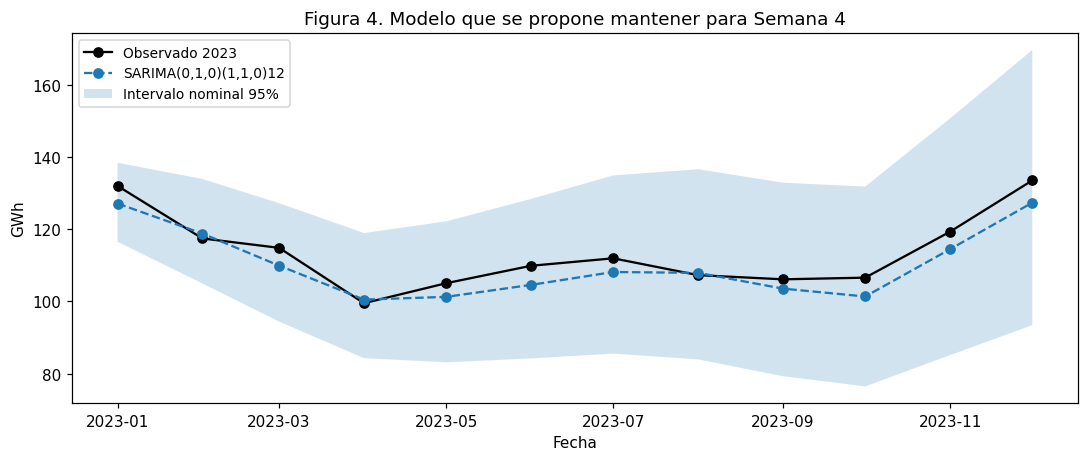

Control temporal superado. No se reajusta ni evalúa 2024 en esta entrega.


In [8]:
# Mantengo SARIMA para esta etapa según los resultados anteriores.
MODELO_ELEGIDO = 'SARIMA(0,1,0)(1,1,0)12'
pronostico_elegido = pred_sarima.copy()
intervalo_elegido = ic_sarima.copy()
# Presento el pronóstico de 2023 junto con su intervalo.
tabla4 = pd.DataFrame({'Observado GWh':y_val,'Pronóstico GWh':pronostico_elegido,
                       'Inferior 95%':intervalo_elegido.iloc[:,0],
                       'Superior 95%':intervalo_elegido.iloc[:,1]})
print('Tabla 4. Modelo elegido:',MODELO_ELEGIDO)
display(tabla4)
# Muestro el modelo que propongo conservar para la etapa siguiente.
fig,ax=plt.subplots(figsize=(10,4.3))
ax.plot(y_val,'o-',color='black',label='Observado 2023')
ax.plot(pronostico_elegido,'o--',label=MODELO_ELEGIDO)
ax.fill_between(y_val.index,intervalo_elegido.iloc[:,0],intervalo_elegido.iloc[:,1],alpha=.2,label='Intervalo nominal 95%')
ax.set(title='Figura 4. Modelo que se propone mantener para Semana 4',xlabel='Fecha',ylabel='GWh')
ax.legend(fontsize=9)
mostrar_figura(fig,'s3_04_seleccion.png')
# Confirmo que la validación sea 2023 y que el entrenamiento termine en 2022.
assert y_val.index.year.unique().tolist()==[2023]
assert z_train.index.max()==pd.Timestamp('2022-12-01')
print('Control temporal superado. No se reajusta ni evalúa 2024 en esta entrega.')

### Interpretación

Mantengo SARIMA(0,1,0)(1,1,0)₁₂, sin constante ni variables exógenas, porque lo seleccioné en Formativa 2. En esta entrega evalúo si los componentes avanzados aportan evidencia para cambiarlo.

Tres resultados sostienen la decisión: (1) H = 0,5837 con n = 83 no se acompaña de un decaimiento positivo lento de la ACF y puede reflejar sesgo R/S; (2) ARCH-LM p = 0,7863 y Ljung–Box de cuadrados p = 0,8287 no respaldan volatilidad condicional detectable; (3) ARFIMA empeora RMSE de 4,1214 a 4,1922 GWh, mientras GARCH solo reduce el ancho medio de 46,2602 a 45,6387 GWh y mantiene 12/12 meses cubiertos.

No se elige por la ausencia aislada de significancia: se integran diagnósticos, contraste predictivo, incertidumbre y parsimonia en consumo eléctrico comercial mensual. Se descartan ambos añadidos como modelo final de esta etapa, aunque se estimaron para contrastarlos.

La principal limitación es una sola ventana de validación de doce meses, reutilizada desde Semana 2, junto con 83 residuos y posibles cambios estructurales. El pico negativo de ACF en 24 merece revisión futura; una diferenciación fraccional no lo resuelve automáticamente.

La Tabla 4 y Figura 4 utilizan efectivamente el modelo elegido para 2023. Para Semana 4 se propone conservar esta especificación y revisar los diagnósticos al ampliar el entrenamiento según sus instrucciones. No se reajusta con 2023 ni se abre 2024 ahora.

## Conclusiones

1. Hurst ligeramente mayor que 0,5 no basta para inferir memoria larga. Su contraste con ruido blanco de igual tamaño, la ACF y la validación no justifica añadir el componente fraccional.
2. Se estimó GARCH(1,1) con restricciones y convergencia; las pruebas originales y posteriores no muestran evidencia suficiente para adoptarlo. Persistencia estimada no equivale a significancia.
3. SARIMA conserva el mejor RMSE y MAE entre las alternativas puntuales contrastadas. Las bandas GARCH apenas cambian el ancho, con idéntica cobertura descriptiva.
4. La conclusión negativa está respaldada cuantitativamente y se mantiene condicionada a muestra corta, dependencia residual en 24 y validación de un año.

### Trazabilidad con la rúbrica de Formativa 3

| Criterio | Evidencia implementada | Ubicación |
|---|---|---|
| Memoria larga, ID 3.1, 9 puntos | H, d, n, ACF hasta 36, sensibilidad a falsos positivos y contraste ARFIMA mínimo | Sección 1, Tabla 1, Figura 1; errores en Tabla 3 |
| Volatilidad, ID 3.1, 9 puntos | ACF de cuadrados, Ljung–Box(12), ARCH-LM, ω/α/β, persistencia, convergencia y residuos estandarizados | Sección 2, Tablas 2a–2b, Figura 2 |
| Contraste, ID 3.1, 9 puntos | RMSE/MAE de tres pronósticos, cobertura y ancho de dos intervalos, misma validación | Sección 3, Tabla 3, Figura 3 |
| Selección, ID 3.2, 9 puntos | Modelo elegido y utilizado, evidencia, alternativas, consecuencia y limitación | Hoja de decisiones y sección 4, Tabla 4, Figura 4 |

**Control técnico:** se conserva semilla 505, hash del CSV, versiones, rutas portables y exclusión de 2024. Las cuatro interpretaciones tienen menos de 250 palabras. Cada cifra de la hoja se obtiene del código; las cifras narrativas corresponden a la ejecución guardada y deben actualizarse si cambia el CSV, el entorno o la especificación. La revisión de estos requisitos no garantiza una calificación.

## 10. Referencias bibliográficas
### 10.1 Referencias bibliográficas

Rosas, H. (2026, 12 de octubre). *MCDI505: Guía de compañía. Semana 3* [Guía docente]. Universidad Andrés Bello. `MCDI505_S3_guia_de_compania.pdf`. Secciones utilizadas: bloques 1–4, diferencias entre sesión y entrega y errores frecuentes.

Universidad Andrés Bello. (s. f.-a). *Análisis de series de tiempo (MCDI505). Formativa 3: Hoja de decisiones: modelos avanzados (ARFIMA / GARCH)* [Instrucciones y rúbrica, versión 2]. `MCDI505_Formativa3_instrucciones_v2.pdf`.

Universidad Andrés Bello. (s. f.-b). *MCDI505: Semana 3. Modelos avanzados (ARFIMA / GARCH)* [Plantilla de notebook]. `mcdi505_s3_plantilla.ipynb`. Fuente de las siete funciones de apoyo y de la construcción de las bandas GARCH.

Espinoza Muñoz, L. R. (2026, 14 de octubre). *MCDI505: Formativa 02. Modelos clásicos de series de tiempo (ARIMA / SARIMA)* [Notebook de trabajo]. `mcdi505_s2lespinoza(2).ipynb`. Fuente de la especificación M4, estructura de reproducibilidad y convención de retransformación.

**Procedencia:** `consumo_electrico_litoral_depurado.csv`, archivo del caso usado en Semana 2. La huella SHA-256 se registra en configuración. No se atribuye al archivo una procedencia pública no verificada. Las referencias siguientes fundamentan los métodos; la implementación específica y sus aproximaciones se describen en cada sección.

### 10.2 Referencias de los métodos

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5th ed.). Wiley.

Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association, 74*(366a), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Hosking, J. R. M. (1981). Fractional differencing. *Biometrika, 68*(1), 165–176. https://doi.org/10.1093/biomet/68.1.165

Hurst, H. E. (1951). Long-term storage capacity of reservoirs. *Transactions of the American Society of Civil Engineers, 116*(1), 770–799. https://doi.org/10.1061/TACEAT.0006518

Ljung, G. M., & Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

## 11. Declaración de uso de inteligencia artificial

En la revisión de esta entrega se utilizó, mediante su asistente de programación, para revisar el código y la redacción, ejecutar el notebook en un entorno limpio, sincronizar la interpretación con la Tabla 3 y completar las referencias metodológicas.
